In [1]:
!pwd

/content


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
%cd /content/drive/MyDrive/ML_game_recommendation

/content/drive/MyDrive/ML_game_recommendation


## Steam recommendations on steam (A)

**Dataset A: Game Recommendations on Steam**

**Source:** https://www.kaggle.com/datasets/antonkozyriev/game-recommendations-on-steam

**Dataset Description**

Dataset A는 Steam 게임 정보와 사용자 리뷰 데이터를 포함한다.

주요 파일은 다음과 같다.

- `games.csv`: 게임 ID, 제목, 출시일, 운영체제 지원 여부, 평점 등
- `recommendations.csv`: 사용자별 게임 추천 여부 및 플레이 기록
- `games_metadata.json`: 게임 설명 및 태그 정보



### games.csv

**Dataset Description**

`games.csv`는 Steam 게임의 기본 정보와 운영체제 지원 여부, 사용자 평가 정보를 포함한다.

주요 컬럼은 다음과 같다.

| 컬럼 | 설명 |
|---|---|
| `app_id` | Steam 게임 고유 ID |
| `title` | 게임 제목 |
| `date_release` | 게임 출시일 |
| `win` | Windows 지원 여부 |
| `mac` | macOS 지원 여부 |
| `linux` | Linux 지원 여부 |
| `rating` | 게임 평가 등급 |
| `positive_ratio` | 긍정적 리뷰 비율 |
| `user_reviews` | 사용자 리뷰 수 |
| `price_final` | 게임 최종 가격 |

**분석 목적**

- 전체 게임 데이터의 크기와 컬럼 구조 확인
- 결측치 및 중복 데이터 확인
- 운영체제별 게임 지원 여부 분석
- Linux 지원 게임의 수와 비율 확인
- Linux 지원 게임만 추출하여 추천 대상 게임 목록 구성

**분석 결과**

- 전체 게임: 50,872개
- 전체 컬럼: 13개
- Linux 지원 게임: 9,041개
- Linux 지원 게임 비율: 약 17.77%
- Linux 게임 중 리뷰가 존재하는 게임: 6,630개
- Linux 게임과 메타데이터 연결: 9,041개 (100%)

**분석 해석**

전체 50,872개 게임 중 약 17.77%가 Linux를 공식 지원하는 것으로 나타났다.

Linux 지원 게임 9,041개 중 6,630개에서 사용자 리뷰가 확인되었다.

따라서 콘텐츠 기반 필터링은 Linux 지원 게임의 메타데이터를 활용하고, 협업 필터링은 사용자 리뷰가 존재하는 Linux 게임을 중심으로 학습 데이터를 구성할 수 있다.

**Model Application**

- `app_id`: 게임 정보와 사용자 리뷰 데이터 연결
- `title`: 게임명 표시 및 다른 데이터셋과 매칭
- `linux`: Linux 지원 게임 필터링
- `rating`, `positive_ratio`, `user_reviews`: 게임 평가 정보 분석 및 추천 결과 보조 지표
- `price_final`: 가격 조건을 활용한 추천 결과 필터링에 활용 가능

Linux 지원 여부를 기준으로 추천 후보를 제한하여 프로젝트 목표에 맞는 게임 추천 시스템을 구현한다.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

games = pd.read_csv("games.csv")

print("데이터 크기:", games.shape)
print("\n컬럼 목록:")
print(games.columns.tolist())

print("\n상위 5개 데이터:")
display(games.head())

데이터 크기: (50872, 13)

컬럼 목록:
['app_id', 'title', 'date_release', 'win', 'mac', 'linux', 'rating', 'positive_ratio', 'user_reviews', 'price_final', 'price_original', 'discount', 'steam_deck']

상위 5개 데이터:


,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True
1,22364,BRINK: Agents of Change,2011-08-03,True,False,False,Positive,85,21,2.99,2.99,0.0,True
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
3,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True
4,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True


In [5]:
# 1. 데이터 타입 및 기본 정보
games.info()

# 2. 결측치 확인
print("\n결측치 개수:")
display(games.isnull().sum())

# 3. 중복 데이터 확인
print("\n중복 행 개수:", games.duplicated().sum())

# 4. 기초 통계량
display(games.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50872 entries, 0 to 50871
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   app_id          50872 non-null  int64  
 1   title           50872 non-null  object 
 2   date_release    50872 non-null  object 
 3   win             50872 non-null  bool   
 4   mac             50872 non-null  bool   
 5   linux           50872 non-null  bool   
 6   rating          50872 non-null  object 
 7   positive_ratio  50872 non-null  int64  
 8   user_reviews    50872 non-null  int64  
 9   price_final     50872 non-null  float64
 10  price_original  50872 non-null  float64
 11  discount        50872 non-null  float64
 12  steam_deck      50872 non-null  bool   
dtypes: bool(4), float64(3), int64(3), object(3)
memory usage: 3.7+ MB

결측치 개수:


,0
app_id,0
title,0
date_release,0
win,0
mac,0
linux,0
rating,0
positive_ratio,0
user_reviews,0
price_final,0



중복 행 개수: 0


,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
count,5.087200e+04,50872,50872,50872,50872,50872,50872,50872.000000,5.087200e+04,50872.000000,50872.000000,50872.000000,50872
unique,NaN,50751,4292,2,2,2,9,NaN,NaN,NaN,NaN,NaN,2
top,NaN,Loop,2020-06-18,True,False,False,Positive,NaN,NaN,NaN,NaN,NaN,True
freq,NaN,4,92,50076,37854,41831,13502,NaN,NaN,NaN,NaN,NaN,50870
mean,1.055224e+06,NaN,NaN,NaN,NaN,NaN,NaN,77.052033,1.824425e+03,8.620325,8.726788,5.592212,NaN
std,6.103249e+05,NaN,NaN,NaN,NaN,NaN,NaN,18.253592,4.007352e+04,11.514164,11.507021,18.606679,NaN
min,1.000000e+01,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000e+01,0.000000,0.000000,0.000000,NaN
25%,5.287375e+05,NaN,NaN,NaN,NaN,NaN,NaN,67.000000,1.900000e+01,0.990000,0.990000,0.000000,NaN
50%,9.860850e+05,NaN,NaN,NaN,NaN,NaN,NaN,81.000000,4.900000e+01,4.990000,4.990000,0.000000,NaN
75%,1.524895e+06,NaN,NaN,NaN,NaN,NaN,NaN,91.000000,2.060000e+02,10.990000,11.990000,0.000000,NaN


linux
False    41831
True      9041
Name: count, dtype: int64

전체 게임 수: 50872
Linux 지원 게임 수: 9041
Linux 지원 비율: 17.77%


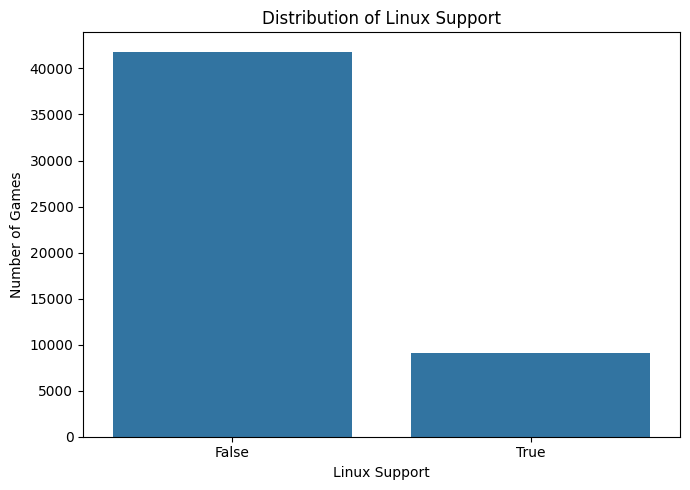

In [6]:
# STEP 3. Linux 지원 게임 분석

# Linux 지원 여부 확인
linux_counts = games["linux"].value_counts()
print(linux_counts)

# Linux 지원 게임 추출
linux_games = games[games["linux"] == True].copy()

# 비율 계산
linux_ratio = len(linux_games) / len(games) * 100

print("\n전체 게임 수:", len(games))
print("Linux 지원 게임 수:", len(linux_games))
print(f"Linux 지원 비율: {linux_ratio:.2f}%")

# 그래프
plt.figure(figsize=(7, 5))

sns.countplot(
    data=games,
    x="linux",
    order=[False, True]
)

plt.title("Distribution of Linux Support")
plt.xlabel("Linux Support")
plt.ylabel("Number of Games")
plt.tight_layout()
plt.show()

Linux 게임 가격 통계:


,price_final
count,9041.000000
mean,8.353095
std,11.593124
min,0.000000
25%,1.990000
50%,4.990000
75%,9.990000
max,199.990000


무료 게임 수: 1294


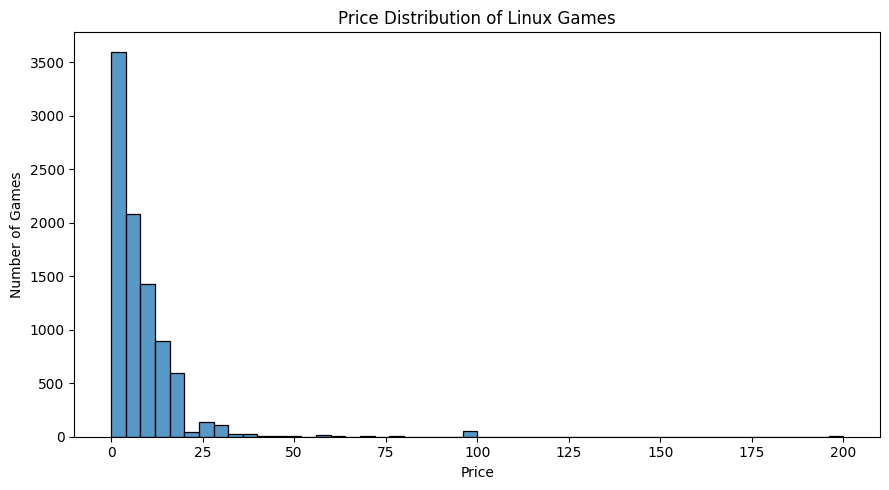

In [7]:
# STEP 4-1. Linux 게임 가격 분석

print("Linux 게임 가격 통계:")
display(linux_games["price_final"].describe())

print("무료 게임 수:",
      (linux_games["price_final"] == 0).sum())

plt.figure(figsize=(9, 5))

sns.histplot(
    data=linux_games,
    x="price_final",
    bins=50
)

plt.title("Price Distribution of Linux Games")
plt.xlabel("Price")
plt.ylabel("Number of Games")
plt.tight_layout()
plt.show()

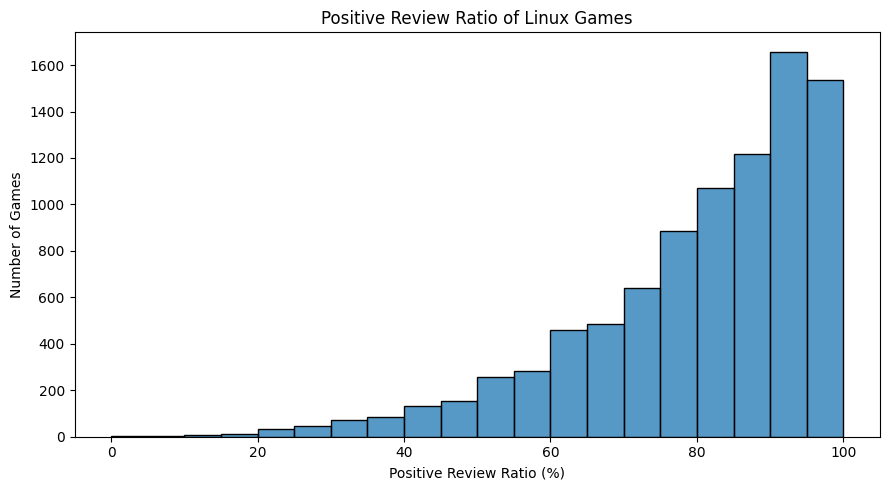

평균 긍정 평가 비율: 79.73177745824577


In [8]:
# STEP 4-2. 긍정 평가 비율 분석

plt.figure(figsize=(9, 5))

sns.histplot(
    data=linux_games,
    x="positive_ratio",
    bins=20
)

plt.title("Positive Review Ratio of Linux Games")
plt.xlabel("Positive Review Ratio (%)")
plt.ylabel("Number of Games")
plt.tight_layout()
plt.show()

print("평균 긍정 평가 비율:",
      linux_games["positive_ratio"].mean())

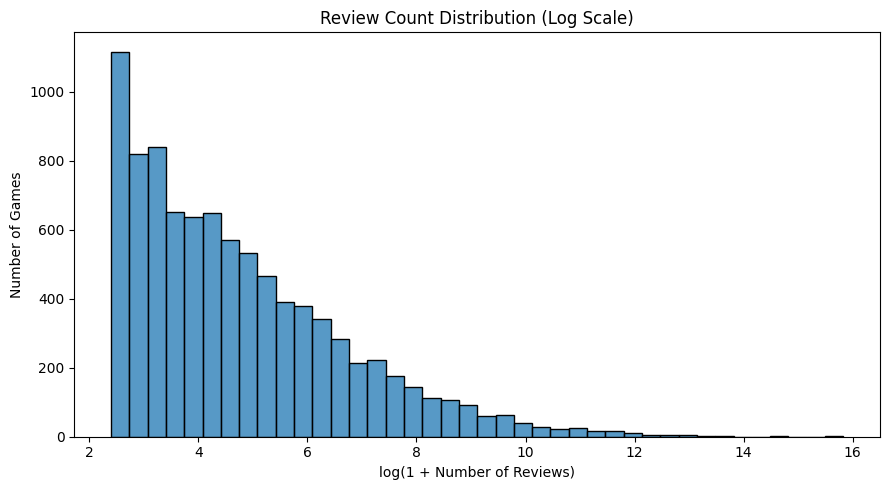

In [9]:
# STEP 4-3. 리뷰 수 분석

linux_games["log_reviews"] = np.log1p(
    linux_games["user_reviews"]
)

plt.figure(figsize=(9, 5))

sns.histplot(
    data=linux_games,
    x="log_reviews",
    bins=40
)

plt.title("Review Count Distribution (Log Scale)")
plt.xlabel("log(1 + Number of Reviews)")
plt.ylabel("Number of Games")
plt.tight_layout()
plt.show()

### recommendations.csv

**Dataset Description**

`recommendations.csv`는 Steam 사용자들의 게임 리뷰 및 플레이 기록을 포함한다.

주요 컬럼은 다음과 같다.

| 컬럼 | 설명 |
|---|---|
| `app_id` | Steam 게임 고유 ID |
| `user_id` | 사용자 고유 ID |
| `is_recommended` | 게임 추천 여부 (True/False) |
| `hours` | 게임 플레이 시간 |
| `date` | 리뷰 작성 날짜 |
| `helpful` | 리뷰가 유용하다고 평가받은 횟수 |
| `funny` | 리뷰가 재미있다고 평가받은 횟수 |
| `review_id` | 리뷰 고유 ID |

**분석 목적**

- 사용자 리뷰 데이터의 크기와 컬럼 구조 확인
- 결측치 및 중복 데이터 확인
- 긍정적·부정적 리뷰 분포 분석
- Linux 지원 게임의 리뷰 데이터 추출
- 사용자별·게임별 리뷰 수 분포 분석
- 사용자–게임 상호작용 행렬의 희소성 확인

**분석 결과**

- 데이터 구조 확인을 위해 최초 10,000개 리뷰를 샘플로 분석
- 데이터 컬럼: 8개
- Linux 지원 게임: 6,630개 (리뷰가 존재하는 게임 기준)
- Linux 게임 리뷰: 11,584,426개
- Linux 게임 리뷰 사용자: 5,955,837명
- 사용자–게임 행렬 밀도: 0.0293%
- 사용자–게임 행렬 희소성: 99.9707%

**사용자별 Linux 게임 리뷰 수 분포**

| 리뷰 수 | 사용자 수 |
|---|---:|
| 1개 | 4,032,369 |
| 2~4개 | 1,532,399 |
| 5~9개 | 285,639 |
| 10개 이상 | 105,430 |

**게임별 리뷰 수 분포**

- 리뷰 5개 미만 게임: 236개
- 리뷰 10개 이상 게임: 5,816개

**분석 해석**

사용자–게임 상호작용 행렬의 희소성이 약 99.97%로 매우 높아 대부분의 사용자가 소수의 게임에 대해서만 리뷰를 작성한 것으로 나타났다.

특히 Linux 게임 리뷰가 1개뿐인 사용자가 많아 협업 필터링에서 데이터 희소성 문제가 발생할 가능성이 있다.

따라서 사용자 간 유사도보다는 게임 간 유사도를 계산하는 **Item-Based Collaborative Filtering (KNN)** 방식을 우선 고려한다.

또한 리뷰가 적은 게임은 유사도 계산의 신뢰도가 낮을 수 있으므로 최소 상호작용 수를 기준으로 필터링하는 방안을 검토한다.

**Model Application**

- `user_id`, `app_id`: 사용자–게임 상호작용 행렬 구성
- `is_recommended`: 긍정적·부정적 선호 정보
- `hours`: 플레이 시간 기반 선호도 가중치 검토
- Linux 지원 게임만 필터링하여 협업 필터링 모델 학습에 활용

In [10]:
# STEP 5-1. 사용자 리뷰 데이터 구조 확인

import pandas as pd

reviews_sample = pd.read_csv(
    "recommendations.csv",
    nrows=10000
)

print("데이터 크기:", reviews_sample.shape)

print("\n컬럼 목록:")
print(reviews_sample.columns.tolist())

print("\n상위 5개 데이터:")
display(reviews_sample.head())

print("\n데이터 타입:")
reviews_sample.info()


데이터 크기: (10000, 8)

컬럼 목록:
['app_id', 'helpful', 'funny', 'date', 'is_recommended', 'hours', 'user_id', 'review_id']

상위 5개 데이터:


,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,975370,0,0,2022-12-12,True,36.3,51580,0
1,304390,4,0,2017-02-17,False,11.5,2586,1
2,1085660,2,0,2019-11-17,True,336.5,253880,2
3,703080,0,0,2022-09-23,True,27.4,259432,3
4,526870,0,0,2021-01-10,True,7.9,23869,4



데이터 타입:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   app_id          10000 non-null  int64  
 1   helpful         10000 non-null  int64  
 2   funny           10000 non-null  int64  
 3   date            10000 non-null  object 
 4   is_recommended  10000 non-null  bool   
 5   hours           10000 non-null  float64
 6   user_id         10000 non-null  int64  
 7   review_id       10000 non-null  int64  
dtypes: bool(1), float64(1), int64(5), object(1)
memory usage: 556.8+ KB


In [11]:
# STEP 5-2. 표본 데이터 품질 확인

print("결측치:")
display(reviews_sample.isnull().sum())

print("\n중복 행:")
print(reviews_sample.duplicated().sum())

print("\n기초 통계:")
display(reviews_sample.describe(include="all"))


결측치:


,0
app_id,0
helpful,0
funny,0
date,0
is_recommended,0
hours,0
user_id,0
review_id,0



중복 행:
0

기초 통계:


,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
count,1.000000e+04,10000.000000,10000.000000,10000,10000,10000.000000,1.000000e+04,10000.00000
unique,NaN,NaN,NaN,2413,2,NaN,NaN,NaN
top,NaN,NaN,NaN,2022-11-22,True,NaN,NaN,NaN
freq,NaN,NaN,NaN,58,8515,NaN,NaN,NaN
mean,6.233737e+05,3.119000,1.114100,NaN,NaN,199.301200,6.239549e+06,4999.50000
std,5.137966e+05,47.322861,34.777266,NaN,NaN,235.063727,3.973735e+06,2886.89568
min,4.400000e+02,0.000000,0.000000,NaN,NaN,0.000000,2.586000e+03,0.00000
25%,2.557100e+05,0.000000,0.000000,NaN,NaN,30.075000,2.887935e+06,2499.75000
50%,3.943600e+05,0.000000,0.000000,NaN,NaN,97.350000,5.757878e+06,4999.50000
75%,1.091500e+06,0.000000,0.000000,NaN,NaN,286.725000,9.347899e+06,7499.25000


In [12]:
# STEP 5-3. Linux 게임과 리뷰 연결 (표본)

linux_reviews_sample = reviews_sample.merge(
    linux_games[["app_id"]],
    on="app_id",
    how="inner"
)

print("표본 리뷰 수:", len(reviews_sample))
print("Linux 게임 관련 표본 리뷰 수:",
      len(linux_reviews_sample))

display(linux_reviews_sample.head())


표본 리뷰 수: 10000
Linux 게임 관련 표본 리뷰 수: 1990


,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,730,0,0,2021-11-30,False,157.5,63209,7
1,255710,0,0,2021-05-21,True,18.7,354512,8
2,289070,0,0,2020-05-26,True,397.5,454422,9
3,289070,0,0,2020-05-29,True,244.1,261528,18
4,392160,3,0,2018-12-26,False,320.5,408750,19


In [13]:
# STEP 5-4. 전체 리뷰 데이터 분석

import pandas as pd

total_reviews = 0
positive_reviews = 0
linux_review_count = 0

# Linux 게임 ID 집합
linux_ids = set(linux_games["app_id"])

# 전체 CSV를 나누어서 읽기
for chunk in pd.read_csv(
    "recommendations.csv",
    chunksize=100000
):

    # 전체 리뷰 수
    total_reviews += len(chunk)

    # 긍정 리뷰 수
    positive_reviews += chunk["is_recommended"].sum()

    # Linux 게임 리뷰 수
    linux_review_count += (
        chunk["app_id"].isin(linux_ids).sum()
    )

print("전체 리뷰 수:", total_reviews)

print("긍정 리뷰 수:", positive_reviews)

print(
    "전체 긍정 리뷰 비율:",
    round(positive_reviews / total_reviews * 100, 2),
    "%"
)

print("Linux 게임 관련 리뷰 수:", linux_review_count)

print(
    "Linux 리뷰 비율:",
    round(linux_review_count / total_reviews * 100, 2),
    "%"
)


전체 리뷰 수: 41154794
긍정 리뷰 수: 35304398
전체 긍정 리뷰 비율: 85.78 %
Linux 게임 관련 리뷰 수: 11584426
Linux 리뷰 비율: 28.15 %


In [14]:
from collections import Counter
import pandas as pd

# 사용자별 리뷰 수 저장
user_counter = Counter()

for chunk in pd.read_csv(
    "recommendations.csv",
    usecols=["user_id"],
    chunksize=500000
):
    user_counter.update(
        chunk["user_id"].value_counts().to_dict()
    )

# Series 변환
user_counts = pd.Series(user_counter, dtype="int64")

print("전체 사용자 수:", len(user_counts))

print("\n사용자별 리뷰 수 통계:")
display(user_counts.describe())

print("\n리뷰 5개 이상 사용자:",
      (user_counts >= 5).sum())

print("리뷰 10개 이상 사용자:",
      (user_counts >= 10).sum())


전체 사용자 수: 13781059

사용자별 리뷰 수 통계:


,0
count,1.378106e+07
mean,2.986330e+00
std,8.118011e+00
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,3.000000e+00
max,6.045000e+03



리뷰 5개 이상 사용자: 1910831
리뷰 10개 이상 사용자: 680812


In [15]:
# STEP 5-6. Linux 게임 사용자별 리뷰 수 분석

from collections import Counter

linux_ids = set(linux_games["app_id"])

linux_user_counter = Counter()
linux_game_counter = Counter()

for chunk in pd.read_csv(
    "recommendations.csv",
    usecols=["user_id", "app_id", "is_recommended"],
    chunksize=500000
):
    # Linux 지원 게임만 선택
    chunk = chunk[
        chunk["app_id"].isin(linux_ids)
    ]

    # 사용자별 리뷰 수 누적
    linux_user_counter.update(
        chunk["user_id"].value_counts().to_dict()
    )

    # 게임별 리뷰 수 누적
    linux_game_counter.update(
        chunk["app_id"].value_counts().to_dict()
    )

linux_user_counts = pd.Series(
    linux_user_counter, dtype="int64"
)

linux_game_counts = pd.Series(
    linux_game_counter, dtype="int64"
)

print("Linux 게임 리뷰 사용자 수:",
      len(linux_user_counts))

print("리뷰가 있는 Linux 게임 수:",
      len(linux_game_counts))

print("\nLinux 사용자별 리뷰 수:")
display(linux_user_counts.describe())

print("\nLinux 게임별 리뷰 수:")
display(linux_game_counts.describe())

print("\nLinux 게임 리뷰 5개 이상 사용자:",
      (linux_user_counts >= 5).sum())

print("Linux 게임 리뷰 10개 이상 사용자:",
      (linux_user_counts >= 10).sum())


Linux 게임 리뷰 사용자 수: 5955837
리뷰가 있는 Linux 게임 수: 6630

Linux 사용자별 리뷰 수:


,0
count,5.955837e+06
mean,1.945054e+00
std,3.581745e+00
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,2.000000e+00
max,1.431000e+03



Linux 게임별 리뷰 수:


,0
count,6630.000000
mean,1747.273906
std,10571.059244
min,1.000000
25%,19.000000
50%,64.500000
75%,324.000000
max,319492.000000



Linux 게임 리뷰 5개 이상 사용자: 391069
Linux 게임 리뷰 10개 이상 사용자: 105430


In [16]:
# STEP 6. Linux 사용자-게임 행렬 희소성

n_users = len(linux_user_counts)
n_games = len(linux_game_counts)

# 이전 단계에서 계산한 Linux 리뷰 행 수
n_interactions = linux_review_count

total_possible = n_users * n_games

density = n_interactions / total_possible * 100
sparsity = 100 - density

print("사용자 수:", n_users)
print("게임 수:", n_games)
print("리뷰 행 수:", n_interactions)

print(f"근사 밀도: {density:.4f}%")
print(f"근사 희소성: {sparsity:.4f}%")


사용자 수: 5955837
게임 수: 6630
리뷰 행 수: 11584426
근사 밀도: 0.0293%
근사 희소성: 99.9707%


In [17]:
# 사용자별 Linux 리뷰 수 분포

print("Linux 리뷰 1개인 사용자:",
      (linux_user_counts == 1).sum())

print("Linux 리뷰 2~4개인 사용자:",
      ((linux_user_counts >= 2) &
       (linux_user_counts < 5)).sum())

print("Linux 리뷰 5~9개인 사용자:",
      ((linux_user_counts >= 5) &
       (linux_user_counts < 10)).sum())

print("Linux 리뷰 10개 이상 사용자:",
      (linux_user_counts >= 10).sum())

# 게임별 리뷰 수 분포
print("\n리뷰 5개 미만인 Linux 게임:",
      (linux_game_counts < 5).sum())

print("리뷰 10개 이상인 Linux 게임:",
      (linux_game_counts >= 10).sum())


Linux 리뷰 1개인 사용자: 4032369
Linux 리뷰 2~4개인 사용자: 1532399
Linux 리뷰 5~9개인 사용자: 285639
Linux 리뷰 10개 이상 사용자: 105430

리뷰 5개 미만인 Linux 게임: 236
리뷰 10개 이상인 Linux 게임: 5816


### games_metadata.json

**Dataset Description**

`games_metadata.json`은 Steam 게임의 설명(description)과 태그(tags) 정보를 포함하는 JSON Lines 형식의 데이터셋이다.

게임의 텍스트 정보를 활용하여 콘텐츠 기반 추천 모델을 구현하는 데 사용한다.

주요 컬럼은 다음과 같다.

| 컬럼 | 설명 |
|---|---|
| `app_id` | Steam 게임 고유 ID |
| `description` | 게임의 특징과 내용을 설명하는 텍스트 |
| `tags` | 게임의 장르, 플레이 방식, 분위기 등을 나타내는 태그 |

**분석 목적**

- JSON 데이터의 구조와 컬럼 확인
- 결측치 및 중복 데이터 확인
- 설명과 태그가 비어 있는 게임 분석
- `games.csv`의 Linux 지원 게임과 메타데이터 연결
- Linux 게임의 주요 태그 분포 분석
- 게임 설명 텍스트 길이 분포 분석
- 콘텐츠 기반 필터링에 활용 가능한 게임 수 확인

**분석 결과**

- 전체 메타데이터: 50,872개
- 전체 컬럼: 3개
- 결측치: 0개
- 중복 행 및 중복 `app_id`: 0개
- 설명이 비어 있는 게임: 10,373개
- 태그가 비어 있는 게임: 1,244개
- 설명과 태그가 모두 없는 게임: 1,229개

**Linux 게임 메타데이터 분석**

| 항목 | 게임 수 |
|---|---:|
| 전체 Linux 게임 | 9,041 |
| 메타데이터 연결 성공 | 9,041 |
| 설명이 비어 있는 게임 | 2,112 |
| 태그가 비어 있는 게임 | 184 |
| 설명과 태그가 모두 없는 게임 | 182 |
| 텍스트 활용 가능 게임 | 8,859 |

**텍스트 활용 가능 비율: 97.99%**

**주요 태그 분포**

Linux 게임에서 빈번하게 나타난 태그는 다음과 같다.

- Indie
- Singleplayer
- Adventure
- Action
- Casual
- 2D
- Strategy
- Simulation
- RPG
- Puzzle

**게임 설명 길이 분석**

- 평균 설명 길이: 약 154자
- 중앙값: 167자
- 최소 길이: 0자
- 최대 길이: 342자

**분석 해석**

전체 Linux 게임 9,041개 중 8,859개(97.99%)가 설명 또는 태그 정보를 포함하고 있어 콘텐츠 기반 추천 모델에 활용할 수 있다.

일부 게임은 설명이 비어 있지만 태그 정보를 보유하고 있으므로 두 정보를 결합하여 활용하는 것이 효과적이다.

또한 Indie, Singleplayer, Adventure 등의 태그가 높은 빈도로 나타나며, 게임의 장르와 특징을 표현하는 주요 정보로 활용할 수 있다.

**Model Application**

- `app_id`: `games.csv`와 메타데이터 연결
- `description`: TF-IDF 기반 게임 텍스트 벡터 생성
- `tags`: 게임의 장르 및 특징을 표현하는 텍스트 정보
- `description` + `tags`: 통합 텍스트 특징 생성
- Cosine Similarity: 게임 간 콘텐츠 유사도 계산

설명과 태그가 모두 없는 182개 게임은 텍스트 기반 유사도 계산이 어려우므로 별도 처리하거나 콘텐츠 기반 추천 후보에서 제외하는 방안을 검토한다.

In [18]:
import json
import pandas as pd

# JSON 파일 앞부분 확인
with open(
    "games_metadata.json",
    "r",
    encoding="utf-8"
) as f:
    for _ in range(3):
        line = f.readline()
        print(line[:500])
        print("-" * 50)


{"app_id":13500,"description":"Enter the dark underworld of Prince of Persia Warrior Within, the sword-slashing sequel to the critically acclaimed Prince of Persia: The Sands of Time™. Hunted by Dahaka, an immortal incarnation of Fate seeking divine retribution, the Prince embarks upon a path of both carnage and mystery to defy his preordained death.","tags":["Action","Adventure","Parkour","Third Person","Great Soundtrack","Singleplayer","Platformer","Time Travel","Atmospheric","Classic","Hack a
--------------------------------------------------
{"app_id":22364,"description":"","tags":["Action"]}

--------------------------------------------------
{"app_id":113020,"description":"Monaco: What's Yours Is Mine is a single player or co-op heist game. Assemble a crack team of thieves, case the joint, and pull off the perfect heist.","tags":["Co-op","Stealth","Indie","Heist","Local Co-Op","Strategy","Online Co-Op","Top-Down","Action","Multiplayer","Crime","Casual","Great Soundtrack","Adventu

In [19]:
# STEP 7-1. JSON Lines 데이터 불러오기

import pandas as pd

metadata = pd.read_json(
    "games_metadata.json",
    lines=True
)

print("메타데이터 크기:", metadata.shape)

print("\n컬럼 목록:")
print(metadata.columns.tolist())

print("\n데이터 타입:")
metadata.info()

print("\n상위 5개 데이터:")
display(metadata.head())


메타데이터 크기: (50872, 3)

컬럼 목록:
['app_id', 'description', 'tags']

데이터 타입:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50872 entries, 0 to 50871
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   app_id       50872 non-null  int64 
 1   description  50872 non-null  object
 2   tags         50872 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.2+ MB

상위 5개 데이터:


,app_id,description,tags
0,13500,Enter the dark underworld of Prince of Persia ...,"[Action, Adventure, Parkour, Third Person, Gre..."
1,22364,,[Action]
2,113020,Monaco: What's Yours Is Mine is a single playe...,"[Co-op, Stealth, Indie, Heist, Local Co-Op, St..."
3,226560,Escape Dead Island is a Survival-Mystery adven...,"[Zombies, Adventure, Survival, Action, Third P..."
4,249050,Dungeon of the Endless is a Rogue-Like Dungeon...,"[Roguelike, Strategy, Tower Defense, Pixel Gra..."


In [20]:
# STEP 7-2. 메타데이터 품질 분석

print("=== 결측치 ===")
display(metadata.isnull().sum())

print("\n=== 중복 검사 ===")
print("중복 행:", metadata.astype(str).duplicated().sum())
print("중복 app_id:", metadata["app_id"].duplicated().sum())

# 빈 설명 확인
empty_description = (
    metadata["description"].fillna("").str.strip() == ""
)

print("\n설명이 비어 있는 게임:",
      empty_description.sum())

# 빈 태그 확인
empty_tags = metadata["tags"].apply(
    lambda x: not isinstance(x, list) or len(x) == 0
)

print("태그가 비어 있는 게임:",
      empty_tags.sum())

# 설명과 태그가 모두 없는 게임
both_empty = empty_description & empty_tags

print("설명과 태그가 모두 없는 게임:",
      both_empty.sum())


=== 결측치 ===


,0
app_id,0
description,0
tags,0



=== 중복 검사 ===
중복 행: 0
중복 app_id: 0

설명이 비어 있는 게임: 10373
태그가 비어 있는 게임: 1244
설명과 태그가 모두 없는 게임: 1229


In [21]:

# STEP 7-3. Linux 게임과 메타데이터 연결

linux_metadata = linux_games.merge(
    metadata,
    on="app_id",
    how="left",
    validate="one_to_one"
)

print("전체 Linux 게임:", len(linux_games))

print("메타데이터가 연결된 게임:",
      linux_metadata["description"].notna().sum())

print("메타데이터가 없는 게임:",
      linux_metadata["description"].isna().sum())

print("\n연결 결과:")
display(
    linux_metadata[
        ["app_id", "title", "description", "tags"]
    ].head()
)


전체 Linux 게임: 9041
메타데이터가 연결된 게임: 9041
메타데이터가 없는 게임: 0

연결 결과:


,app_id,title,description,tags
0,113020,Monaco: What's Yours Is Mine,Monaco: What's Yours Is Mine is a single playe...,"[Co-op, Stealth, Indie, Heist, Local Co-Op, St..."
1,253980,Enclave,Experience incredibly atmospheric and intense ...,"[RPG, Action, Fantasy, Third Person, Hack and ..."
2,29180,Osmos,"Enter the ambient world of Osmos: elegant, phy...","[Indie, Casual, Puzzle, Relaxing, Singleplayer..."
3,245950,Borderlands 2: Headhunter 4: Wedding Day Massacre,,"[Action, RPG, FPS, Co-op, Shooter, Action RPG,..."
4,250460,Bridge Constructor,Become an appraised bridge engineer and archit...,"[Simulation, Casual, Indie, Physics, Puzzle, B..."


In [22]:
# STEP 7-4. Linux 게임 텍스트 품질 분석

# 설명이 비어 있는 게임
linux_empty_desc = (
    linux_metadata["description"]
    .fillna("")
    .str.strip() == ""
)

# 태그가 비어 있는 게임
linux_empty_tags = linux_metadata["tags"].apply(
    lambda x: not isinstance(x, list) or len(x) == 0
)

# 설명과 태그가 모두 없는 게임
linux_both_empty = (
    linux_empty_desc & linux_empty_tags
)

print("전체 Linux 게임:", len(linux_metadata))

print("설명이 비어 있는 Linux 게임:",
      linux_empty_desc.sum())

print("태그가 비어 있는 Linux 게임:",
      linux_empty_tags.sum())

print("설명과 태그 모두 없는 Linux 게임:",
      linux_both_empty.sum())

print("텍스트 정보가 있는 Linux 게임:",
      (~linux_both_empty).sum())

print(
    "텍스트 활용 가능 비율:",
    round((~linux_both_empty).mean() * 100, 2),
    "%"
)


전체 Linux 게임: 9041
설명이 비어 있는 Linux 게임: 2112
태그가 비어 있는 Linux 게임: 184
설명과 태그 모두 없는 Linux 게임: 182
텍스트 정보가 있는 Linux 게임: 8859
텍스트 활용 가능 비율: 97.99 %


전체 고유 태그 수: 432

상위 20개 태그:


,Tag,Count
0,Indie,6089
1,Singleplayer,3997
2,Adventure,3485
3,Action,3455
4,Casual,3212
5,2D,2597
6,Strategy,2502
7,Simulation,2287
8,RPG,1950
9,Puzzle,1589


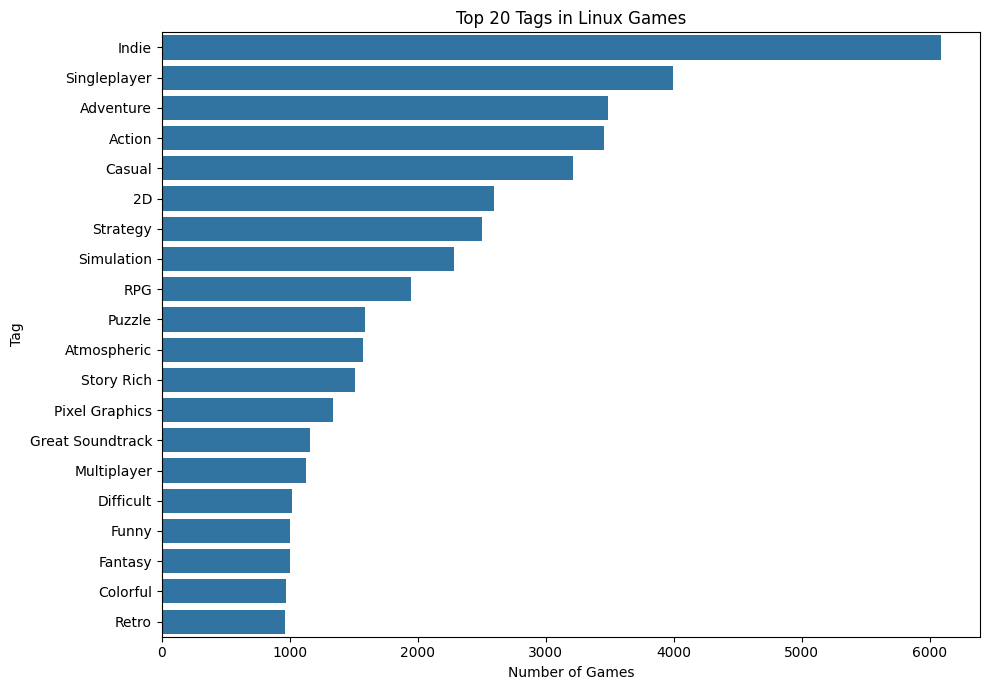

In [23]:
# STEP 7-5. Linux 게임 태그 빈도 분석

from collections import Counter

tag_counter = Counter()

for tags in linux_metadata["tags"]:
    if isinstance(tags, list):
        tag_counter.update(tags)

# 상위 20개 태그
top_tags = pd.DataFrame(
    tag_counter.most_common(20),
    columns=["Tag", "Count"]
)

print("전체 고유 태그 수:", len(tag_counter))

print("\n상위 20개 태그:")
display(top_tags)

# 시각화
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_tags,
    x="Count",
    y="Tag"
)

plt.title("Top 20 Tags in Linux Games")
plt.xlabel("Number of Games")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()


Linux 게임 설명 길이 통계:


,desc_length
count,9041.000000
mean,154.154850
std,108.863456
min,0.000000
25%,43.000000
50%,167.000000
75%,252.000000
max,342.000000


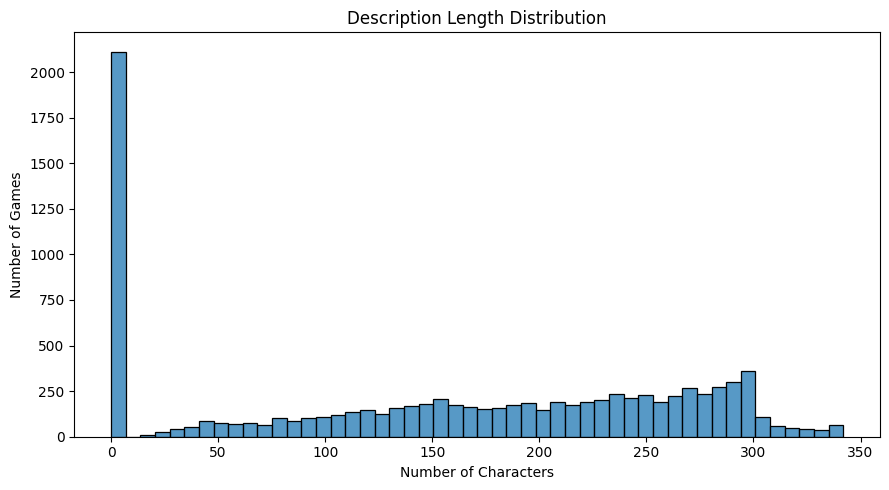

In [24]:
# STEP 7-6. 게임 설명 길이 분석

linux_metadata["desc_length"] = (
    linux_metadata["description"]
    .fillna("")
    .str.len()
)

print("Linux 게임 설명 길이 통계:")
display(linux_metadata["desc_length"].describe())

plt.figure(figsize=(9, 5))

sns.histplot(
    linux_metadata["desc_length"],
    bins=50
)

plt.title("Description Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Games")
plt.tight_layout()
plt.show()


## Steam Games Dataset (B)

Dataset B: Steam Games Dataset

**Source:** https://www.kaggle.com/datasets/artermiloff/steam-games-dataset

**Dataset Description**

Dataset B는 Steam 게임의 기본 정보와 콘텐츠 관련 메타데이터를 포함하는 데이터셋이다.

게임의 장르, 태그, 설명, 가격, 사용자 평가 및 운영체제 지원 여부를 제공하며, Dataset A의 게임 정보를 보완하고 콘텐츠 기반 추천 모델의 특징 데이터를 확장하는 데 활용할 수 있다.

본 프로젝트에서는 2025년 3월 기준의 중복 및 플레이테스트 버전이 정리된 `games_march2025_cleaned.csv` 파일을 사용한다.

**주요 파일**

- `games_march2025_cleaned.csv`: 게임 정보, 장르, 태그, 설명, 가격, Linux 지원 여부 및 사용자 평가 정보


### games_march2025_cleaned.csv

**주요 컬럼**

| 컬럼 | 설명 |
|---|---|
| `appid` | Steam 게임 고유 ID |
| `name` | 게임 제목 |
| `price` | 게임 가격 |
| `short_description` | 게임의 간단한 설명 |
| `linux` | Linux 운영체제 지원 여부 |
| `genres` | 게임 장르 |
| `tags` | 게임 특징을 나타내는 태그 |
| `positive` | 긍정 평가 수 |
| `negative` | 부정 평가 수 |

**분석 목적**

- 데이터셋의 전체 크기와 컬럼 구조 확인
- 결측치 및 중복 데이터 확인
- Linux 지원 게임의 수와 비율 분석
- Dataset A와 공통으로 존재하는 게임 확인
- 게임 설명 및 태그 정보의 활용 가능성 분석
- 콘텐츠 기반 추천 모델에 사용할 추가 메타데이터 확보

**분석 결과**

- 전체 게임: 89,618개
- 전체 컬럼: 9개
- 중복 행: 0개
- 중복 `appid`: 0개
- `short_description` 결측치: 120개
- 나머지 컬럼 결측치: 0개

**Linux 지원 게임 분석**

| 항목 | 게임 수 |
|---|---:|
| 전체 게임 | 89,618 |
| Linux 지원 게임 | 12,627 |
| Linux 미지원 게임 | 76,991 |

**Linux 지원 게임 비율: 약 14.09%**

**Dataset A와 B의 게임 매칭 결과**

| 항목 | 게임 수 |
|---|---:|
| Dataset A Linux 게임 | 9,041 |
| Dataset B Linux 게임 | 12,627 |
| A와 B 공통 Linux 게임 | 6,382 |
| A에만 존재하는 Linux 게임 | 2,659 |
| B에만 존재하는 Linux 게임 | 6,245 |

**Dataset A 기준 매칭률: 70.59%**

**분석 해석**

Dataset B는 Dataset A보다 많은 Linux 지원 게임을 포함하고 있으며, 두 데이터셋에서 공통으로 확인되는 Linux 게임은 6,382개이다.

Dataset A의 Linux 게임 중 약 70.59%가 Dataset B와 연결되므로, 공통 게임의 장르, 태그 및 설명 정보를 보완할 수 있다.

또한 Dataset B에만 존재하는 Linux 게임 6,245개를 통해 추천 후보 게임의 범위를 확장할 가능성이 있다.

다만 Dataset B는 사용자별 게임 상호작용 정보를 포함하지 않으므로 협업 필터링 학습보다는 콘텐츠 기반 추천에 활용하는 것이 적합하다.

**Model Application**

- `appid`: Dataset A의 `app_id`와 연결
- `short_description`: TF-IDF 기반 텍스트 벡터 생성
- `genres`: 게임 장르 기반 유사도 분석
- `tags`: 게임 특징 및 취향 분석
- `price`: 가격 조건에 따른 추천 결과 필터링
- `positive`, `negative`: 게임 평가 정보를 활용한 추천 결과 보조 분석
- `linux`: Linux 지원 게임만 추천하도록 필터링

Dataset A의 사용자 리뷰 및 게임 메타데이터와 Dataset B의 콘텐츠 정보를 결합하여 추천 모델에 활용할 수 있다.

최종적으로 Dataset B는 콘텐츠 기반 추천의 특징 정보를 보완하고, 추천 가능한 Linux 게임의 범위를 확장하는 데 활용한다.

In [25]:
import pandas as pd

# 필요한 컬럼만 선택
cols = [
    "appid", "name", "linux",
    "genres", "tags",
    "short_description",
    "price", "positive", "negative"
]

# B 데이터셋 불러오기
games_b = pd.read_csv(
    "games_march2025_cleaned.csv",
    usecols=cols
)

print("데이터 크기:", games_b.shape)

print("\n컬럼 목록:")
print(games_b.columns.tolist())

print("\n상위 5개 데이터:")
display(games_b.head())

print("\n데이터 타입:")
games_b.info()


데이터 크기: (89618, 9)

컬럼 목록:
['appid', 'name', 'price', 'short_description', 'linux', 'genres', 'positive', 'negative', 'tags']

상위 5개 데이터:


,appid,name,price,short_description,linux,genres,positive,negative,tags
0,730,Counter-Strike 2,0.00,"For over two decades, Counter-Strike has offer...",True,"['Action', 'Free To Play']",7480813,1135108,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'..."
1,578080,PUBG: BATTLEGROUNDS,0.00,Play PUBG: BATTLEGROUNDS for free. Land on str...,False,"['Action', 'Adventure', 'Massively Multiplayer...",1487960,1024436,"{'Survival': 14838, 'Shooter': 12727, 'Battle ..."
2,570,Dota 2,0.00,"Every day, millions of players worldwide enter...",True,"['Action', 'Strategy', 'Free To Play']",1998462,451338,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip..."
3,271590,Grand Theft Auto V Legacy,0.00,Grand Theft Auto V for PC offers players the o...,False,"['Action', 'Adventure']",1719950,250012,"{'Open World': 32644, 'Action': 23539, 'Multip..."
4,359550,Tom Clancy's Rainbow Six® Siege,3.99,"Tom Clancy's Rainbow Six® Siege is an elite, t...",False,['Action'],1152763,218446,"{'FPS': 9831, 'PvP': 9162, 'e-sports': 9072, '..."



데이터 타입:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89618 entries, 0 to 89617
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   appid              89618 non-null  int64  
 1   name               89618 non-null  object 
 2   price              89618 non-null  float64
 3   short_description  89498 non-null  object 
 4   linux              89618 non-null  bool   
 5   genres             89618 non-null  object 
 6   positive           89618 non-null  int64  
 7   negative           89618 non-null  int64  
 8   tags               89618 non-null  object 
dtypes: bool(1), float64(1), int64(3), object(4)
memory usage: 5.6+ MB


In [26]:
print("=== 결측치 ===")
display(games_b.isnull().sum())

print("\n=== 중복 검사 ===")
print("중복 행:", games_b.duplicated().sum())
print("중복 appid:", games_b["appid"].duplicated().sum())

print("\n=== Linux 지원 여부 ===")
print(games_b["linux"].value_counts(dropna=False))

# Linux 게임만 추출
linux_b = games_b[games_b["linux"] == True].copy()

print("\nB의 Linux 게임 수:", len(linux_b))


=== 결측치 ===


,0
appid,0
name,0
price,0
short_description,120
linux,0
genres,0
positive,0
negative,0
tags,0



=== 중복 검사 ===
중복 행: 0
중복 appid: 0

=== Linux 지원 여부 ===
linux
False    76991
True     12627
Name: count, dtype: int64

B의 Linux 게임 수: 12627


In [27]:
# A의 Linux 게임 ID
a_ids = set(games.loc[games["linux"], "app_id"])

# B의 Linux 게임 ID
b_ids = set(linux_b["appid"])

# 공통 게임
common = a_ids & b_ids

print("A Linux 게임:", len(a_ids))
print("B Linux 게임:", len(b_ids))
print("A와 B 공통 게임:", len(common))

print("A에만 있는 게임:", len(a_ids - b_ids))
print("B에만 있는 게임:", len(b_ids - a_ids))

print(
    "A 기준 매칭률:",
    round(len(common) / len(a_ids) * 100, 2),
    "%"
)


A Linux 게임: 9041
B Linux 게임: 12627
A와 B 공통 게임: 6382
A에만 있는 게임: 2659
B에만 있는 게임: 6245
A 기준 매칭률: 70.59 %


In [28]:
# STEP 9-1. A와 B의 Linux 게임 정보 연결

a = linux_metadata.copy()
b = linux_b.copy()

# A의 설명/태그가 비어 있는지 검사
a["a_desc_empty"] = (
    a["description"].fillna("").str.strip() == ""
)
a["a_tags_empty"] = a["tags"].apply(
    lambda x: len(x) == 0 if isinstance(x, list)
    else pd.isna(x) or str(x).strip() in ("", "[]")
)

a["a_both_empty"] = (
    a["a_desc_empty"] & a["a_tags_empty"]
)

# B에서 필요한 컬럼만 선택
b = b[[
    "appid", "short_description",
    "genres", "tags"
]].rename(columns={
    "appid": "app_id",
    "short_description": "b_description",
    "genres": "b_genres",
    "tags": "b_tags"
})

# A를 기준으로 B 정보 연결
merged = a.merge(
    b,
    on="app_id",
    how="left",
    validate="one_to_one"
)

print("A Linux 게임:", len(a))
print("연결 후 게임:", len(merged))
print("B 정보가 있는 게임:",
      merged["app_id"].isin(b["app_id"]).sum())

# A에서 텍스트가 모두 없는 게임 중
# B의 설명으로 보완 가능한 게임
b_desc_available = (
    merged["b_description"]
    .fillna("").str.strip().ne("")
)

recovered = (
    merged["a_both_empty"] & b_desc_available
)

print("A 텍스트 모두 없는 게임:",
      merged["a_both_empty"].sum())
print("B 설명으로 보완 가능한 게임:",
      recovered.sum())

A Linux 게임: 9041
연결 후 게임: 9041
B 정보가 있는 게임: 6382
A 텍스트 모두 없는 게임: 182
B 설명으로 보완 가능한 게임: 125


## Steam Video Game and Bundle Data (C)

Dataset C: Steam Video Game and Bundle Data

Source: https://www.kaggle.com/datasets/pypiahmad/steam-video-game-and-bundle-data

Dataset Description

Dataset C는 Steam 사용자별 게임 보유 및 플레이 기록을 포함한다. 본 프로젝트에서는 australian_users_items.json 파일을 활용하여 추천 시스템의 외부 평가용 사용자–게임 상호작용 데이터를 구성한다.

주요 파일은 다음과 같다.

australian_users_items.json: 사용자별 게임 보유 목록 및 플레이 시간 정보

australian_user_reviews.json: 사용자별 게임 리뷰 및 추천 여부 정보

bundle_data.json: Steam 게임 번들 관련 정보

**Dataset Description**

Dataset C는 Steam 사용자별 게임 보유 및 플레이 기록을 포함한다. 본 프로젝트에서는 `australian_users_items.json`을 활용하여 외부 평가용 사용자–게임 상호작용 데이터를 구성한다.

**분석 목적**
- A, B 데이터셋과 Steam App ID 기준으로 게임 매칭
- Linux 지원 게임의 사용자 플레이 기록 확인
- 추천 시스템의 외부 평가에 사용할 사용자 확보
- 사용자별 게임 수 분포 분석

**분석 결과**
- 전체 기록: 5,153,209건
- 전체 사용자: 70,912명
- 전체 게임: 10,978개
- A+B+C 공통 게임: 2,158개
- 매칭 사용자: 62,029명
- 게임 5개 이상 사용자: 39,398명
- 게임 10개 이상 사용자: 22,901명
- 사용자당 평균 게임 수: 10.27개
- 사용자당 중앙값 게임 수: 7개

**분석 결론**

2시간 이상 플레이한 게임을 긍정 상호작용으로 정의한 결과, 추천 성능 평가에 활용할 수 있는 사용자와 게임 기록을 충분히 확보하였다.


따라서 새로운 C 데이터셋을 외부 평가 데이터로 사용하는 방안을 우선 검토한다. 이후 데이터 중복 및 누수 여부를 확인하고, Recall@10과 NDCG@10을 활용하여 추천 성능을 평가할 예정이다.

In [29]:
import ast
import pandas as pd

# 리뷰 데이터 불러오기
rows = []

with open("australian_user_reviews.json",
          "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            rows.append(ast.literal_eval(line))

reviews_c = pd.json_normalize(
    rows,
    record_path="reviews",
    meta=["user_id"]
)

print("전체 리뷰:", len(reviews_c))
print("전체 사용자:", reviews_c["user_id"].nunique())
print("전체 게임:", reviews_c["item_id"].nunique())

display(reviews_c.head())


전체 리뷰: 59305
전체 사용자: 25458
전체 게임: 3682


,funny,posted,last_edited,item_id,helpful,recommend,review,user_id
0,,"Posted November 5, 2011.",,1250,No ratings yet,True,Simple yet with great replayability. In my opi...,76561197970982479
1,,"Posted July 15, 2011.",,22200,No ratings yet,True,It's unique and worth a playthrough.,76561197970982479
2,,"Posted April 21, 2011.",,43110,No ratings yet,True,Great atmosphere. The gunplay can be a bit chu...,76561197970982479
3,,"Posted June 24, 2014.",,251610,15 of 20 people (75%) found this review helpful,True,I know what you think when you see this title ...,js41637
4,,"Posted September 8, 2013.",,227300,0 of 1 people (0%) found this review helpful,True,For a simple (it's actually not all that simpl...,js41637


In [30]:

# ID 형식 통일
a_ids = set(pd.to_numeric(
    games.loc[games["linux"] == True, "app_id"],
    errors="coerce"
).dropna().astype("int64"))

b_ids = set(pd.to_numeric(
    games_b["appid"], errors="coerce"
).dropna().astype("int64"))

c_ids = set(pd.to_numeric(
    reviews_c["item_id"], errors="coerce"
).dropna().astype("int64"))

print("A Linux 게임:", len(a_ids))
print("B 게임:", len(b_ids))
print("C 리뷰 게임:", len(c_ids))

common = a_ids & b_ids & c_ids

print("A+B+C 공통 게임:", len(common))


A Linux 게임: 9041
B 게임: 89618
C 리뷰 게임: 3682
A+B+C 공통 게임: 865


In [31]:
reviews_c["app_id"] = pd.to_numeric(
    reviews_c["item_id"], errors="coerce"
)

# Linux 지원 + A/B/C 공통 + 긍정 리뷰
c_eval = reviews_c[
    reviews_c["app_id"].isin(common)
    & (reviews_c["recommend"] == True)
].copy()

# 사용자별 서로 다른 게임 수
user_counts = (
    c_eval.groupby("user_id")["app_id"]
    .nunique()
)

print("매칭 사용자:", len(user_counts))
print("게임 5개 이상:", (user_counts >= 5).sum())
print("게임 10개 이상:", (user_counts >= 10).sum())

display(user_counts.describe())


매칭 사용자: 16487
게임 5개 이상: 296
게임 10개 이상: 0


,app_id
count,16487.000000
mean,1.509856
std,0.935768
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,8.000000


In [32]:
import ast
import pandas as pd

# 사용자별 보유 게임 데이터
rows = []

with open("australian_users_items.json",
          "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            rows.append(ast.literal_eval(line))

items_c = pd.json_normalize(
    rows,
    record_path="items",
    meta=["user_id"]
)

print("=== 전체 데이터 ===")
print("전체 기록:", len(items_c))
print("전체 사용자:", items_c["user_id"].nunique())
print("전체 게임:", items_c["item_id"].nunique())

# Steam ID 변환
items_c["app_id"] = pd.to_numeric(
    items_c["item_id"], errors="coerce"
)

# A+B Linux 게임과 매칭
items_common = items_c[
    items_c["app_id"].isin(a_ids & b_ids)
].copy()

# 2시간 이상 플레이한 게임
items_positive = items_common[
    items_common["playtime_forever"] >= 120
].copy()

user_counts_items = (
    items_positive.groupby("user_id")["app_id"]
    .nunique()
)

print("\n=== 평가 가능성 분석 ===")
print("공통 게임:", items_common["app_id"].nunique())
print("매칭 사용자:", len(user_counts_items))
print("게임 5개 이상:", (user_counts_items >= 5).sum())
print("게임 10개 이상:", (user_counts_items >= 10).sum())

display(user_counts_items.describe())


=== 전체 데이터 ===
전체 기록: 5153209
전체 사용자: 70912
전체 게임: 10978

=== 평가 가능성 분석 ===
공통 게임: 2158
매칭 사용자: 62029
게임 5개 이상: 39398
게임 10개 이상: 22901


,app_id
count,62029.000000
mean,10.270615
std,14.286518
min,1.000000
25%,3.000000
50%,7.000000
75%,13.000000
max,668.000000


## A+B 데이터셋 통합 및 C 테스트 데이터셋 구축

In [33]:
import pandas as pd

# A: 게임 정보
games_a = games.copy()

# B: 게임 메타데이터
games_b_clean = games_b.copy()

# C: 사용자 게임 플레이 기록
items_c = items_common.copy()

# 게임 ID 통일
games_a["app_id"] = pd.to_numeric(
    games_a["app_id"], errors="coerce"
)
games_b_clean["appid"] = pd.to_numeric(
    games_b_clean["appid"], errors="coerce"
)
items_c["app_id"] = pd.to_numeric(
    items_c["app_id"], errors="coerce"
)

# 게임 ID 결측치 확인
for name, df, col in [
    ("A", games_a, "app_id"),
    ("B", games_b_clean, "appid"),
    ("C", items_c, "app_id")
]:
    print(f"{name} ID 결측치:", df[col].isna().sum())
    print(f"{name} ID 고유 개수:", df[col].nunique())


A ID 결측치: 0
A ID 고유 개수: 50872
B ID 결측치: 0
B ID 고유 개수: 89618
C ID 결측치: 0
C ID 고유 개수: 2158


In [34]:
# STEP 5-2. 중복 데이터 확인

print("=== A 데이터셋 ===")
print("전체 중복 행:", games_a.duplicated().sum())
print("중복 게임 ID:", games_a["app_id"].duplicated().sum())

print("\n=== B 데이터셋 ===")
print("전체 중복 행:", games_b_clean.duplicated().sum())
print("중복 게임 ID:", games_b_clean["appid"].duplicated().sum())

print("\n=== C 데이터셋 ===")
print("전체 중복 행:", items_c.duplicated().sum())

# 동일 사용자가 동일 게임을 여러 번 기록했는지 확인
print(
    "사용자-게임 중복:",
    items_c.duplicated(subset=["user_id", "app_id"]).sum()
)

print("\n=== 게임 ID 자료형 ===")
print("A:", games_a["app_id"].dtype)
print("B:", games_b_clean["appid"].dtype)
print("C:", items_c["app_id"].dtype)


=== A 데이터셋 ===
전체 중복 행: 0
중복 게임 ID: 0

=== B 데이터셋 ===
전체 중복 행: 0
중복 게임 ID: 0

=== C 데이터셋 ===
전체 중복 행: 15102
사용자-게임 중복: 15113

=== 게임 ID 자료형 ===
A: int64
B: int64
C: int64


In [35]:
# STEP 5-3. C 데이터셋 중복 처리

# 원본 보존
items_c_clean = items_c.copy()

print("중복 제거 전:", len(items_c_clean))

# 완전히 동일한 행 제거
items_c_clean = items_c_clean.drop_duplicates().copy()

print("중복 제거 후:", len(items_c_clean))

# 사용자-게임 중복 확인
duplicate_pairs = items_c_clean[
    items_c_clean.duplicated(
        subset=["user_id", "app_id"],
        keep=False
    )
].sort_values(["user_id", "app_id"])

print("\n남은 사용자-게임 중복 행 수:",
      items_c_clean.duplicated(
          subset=["user_id", "app_id"]
      ).sum())

print("\n중복된 사용자-게임 기록 예시:")
display(duplicate_pairs.head(20))

print("\n컬럼 목록:")
print(items_c_clean.columns.tolist())


중복 제거 전: 1308607
중복 제거 후: 1293505

남은 사용자-게임 중복 행 수: 11

중복된 사용자-게임 기록 예시:


,item_id,item_name,playtime_forever,playtime_2weeks,user_id,app_id
1556733,282070,This War of Mine,1486,1486,76561198079079942,282070
3404683,282070,This War of Mine,1516,1516,76561198079079942,282070
1375435,730,Counter-Strike: Global Offensive,30676,481,76561198080450686,730
3146776,730,Counter-Strike: Global Offensive,30676,451,76561198080450686,730
356660,730,Counter-Strike: Global Offensive,31410,5367,76561198081666970,730
3201731,730,Counter-Strike: Global Offensive,31423,5349,76561198081666970,730
356693,361600,Luna Sky,2,0,76561198081666970,361600
3201764,361600,Luna Sky,9,7,76561198081666970,361600
165759,730,Counter-Strike: Global Offensive,2568,519,Letachal,730
952088,730,Counter-Strike: Global Offensive,2568,479,Letachal,730



컬럼 목록:
['item_id', 'item_name', 'playtime_forever', 'playtime_2weeks', 'user_id', 'app_id']


In [36]:
# STEP 5-4. 사용자-게임 중복 최종 처리

# 원본 보존
items_c_final = items_c_clean.copy()

# 누적 플레이 시간이 가장 큰 기록 우선
items_c_final = items_c_final.sort_values(
    by="playtime_forever",
    ascending=False
)

# 동일 사용자-게임 조합에서 하나만 유지
items_c_final = items_c_final.drop_duplicates(
    subset=["user_id", "app_id"],
    keep="first"
).copy()

print("=== C 데이터셋 최종 정리 ===")
print("최종 기록 수:", len(items_c_final))
print("최종 사용자 수:", items_c_final["user_id"].nunique())
print("최종 게임 수:", items_c_final["app_id"].nunique())

print("\n남은 사용자-게임 중복:",
      items_c_final.duplicated(
          subset=["user_id", "app_id"]
      ).sum())

print("\n결측치 확인:")
print(items_c_final[
    ["user_id", "app_id", "playtime_forever"]
].isna().sum())


=== C 데이터셋 최종 정리 ===
최종 기록 수: 1293494
최종 사용자 수: 65168
최종 게임 수: 2158

남은 사용자-게임 중복: 0

결측치 확인:
user_id             0
app_id              0
playtime_forever    0
dtype: int64


In [37]:
# STEP 6-1. Linux 지원 게임 추출

import pandas as pd

# A 데이터셋 복사
games_a = games.copy()

# Linux 지원 여부 확인
print("Linux 컬럼 자료형:", games_a["linux"].dtype)
print(games_a["linux"].value_counts(dropna=False))

# Linux 지원 게임만 추출
games_linux = games_a[
    games_a["linux"].astype(str).str.lower() == "true"
].copy()

# 게임 ID 숫자형 통일
games_linux["app_id"] = pd.to_numeric(
    games_linux["app_id"],
    errors="coerce"
).astype("Int64")

# 필수 게임 ID가 없는 행 제외
games_linux = games_linux.dropna(
    subset=["app_id"]
).copy()

games_linux["app_id"] = games_linux["app_id"].astype("int64")

print("\n=== STEP 6-1 결과 ===")
print("전체 게임:", len(games_a))
print("Linux 지원 게임:", len(games_linux))
print("Linux 게임 ID 중복:",
      games_linux["app_id"].duplicated().sum())

display(games_linux.head())


Linux 컬럼 자료형: bool
linux
False    41831
True      9041
Name: count, dtype: int64

=== STEP 6-1 결과 ===
전체 게임: 50872
Linux 지원 게임: 9041
Linux 게임 ID 중복: 0


,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
6,253980,Enclave,2013-10-04,True,True,True,Mostly Positive,75,1608,4.99,4.99,0.0,True
13,29180,Osmos,2009-08-18,True,True,True,Very Positive,88,532,9.99,9.99,0.0,True
18,245950,Borderlands 2: Headhunter 4: Wedding Day Massacre,2014-02-11,True,True,True,Very Positive,84,294,0.89,2.99,70.0,True
19,250460,Bridge Constructor,2013-10-16,True,True,True,Mostly Positive,77,716,2.39,19.99,88.0,True


In [38]:
# STEP 6-2. A+B 메타데이터 결합

# B 데이터셋 복사
games_b_train = games_b.copy()

# B 게임 ID 숫자형 통일
games_b_train["appid"] = pd.to_numeric(
    games_b_train["appid"],
    errors="coerce"
)

games_b_train = games_b_train.dropna(
    subset=["appid"]
).copy()

games_b_train["appid"] = games_b_train["appid"].astype("int64")

# B 게임 ID 중복 확인
print("B 게임 ID 중복:",
      games_b_train["appid"].duplicated().sum())

# A와 B 연결에 필요한 컬럼 선택
b_features = games_b_train[
    ["appid", "name", "genres", "tags",
     "short_description", "price"]
].copy()

# 동일한 이름의 컬럼 충돌 방지
b_features = b_features.rename(columns={
    "name": "title_b",
    "genres": "genres_b",
    "tags": "tags_b",
    "short_description": "description_b",
    "price": "price_b"
})

# A + B 결합
games_train = games_linux.merge(
    b_features,
    left_on="app_id",
    right_on="appid",
    how="left",
    validate="one_to_one"
)

print("\n=== STEP 6-2 결과 ===")
print("A Linux 게임:", len(games_linux))
print("결합 후 게임:", len(games_train))

print("B 메타데이터 연결 게임:",
      games_train["appid"].notna().sum())

print("B 메타데이터 미연결 게임:",
      games_train["appid"].isna().sum())

print("중복 게임 ID:",
      games_train["app_id"].duplicated().sum())

display(games_train[
    ["app_id", "title", "genres_b",
     "tags_b", "description_b"]
].head())


B 게임 ID 중복: 0

=== STEP 6-2 결과 ===
A Linux 게임: 9041
결합 후 게임: 9041
B 메타데이터 연결 게임: 6440
B 메타데이터 미연결 게임: 2601
중복 게임 ID: 0


,app_id,title,genres_b,tags_b,description_b
0,113020,Monaco: What's Yours Is Mine,"['Action', 'Adventure', 'Casual', 'Indie', 'St...","{'Co-op': 674, 'Stealth': 425, 'Indie': 404, '...",Monaco: What's Yours Is Mine is a single playe...
1,253980,Enclave,"['Action', 'RPG']","{'RPG': 549, 'Action': 187, 'Fantasy': 148, 'T...",Experience incredibly atmospheric and intense ...
2,29180,Osmos,NaN,NaN,NaN
3,245950,Borderlands 2: Headhunter 4: Wedding Day Massacre,NaN,NaN,NaN
4,250460,Bridge Constructor,"['Casual', 'Indie', 'Simulation']","{'Simulation': 98, 'Casual': 91, 'Indie': 67, ...",Become an appraised bridge engineer and archit...


In [42]:
# STEP 6-2 추가 검증

# B와 연결된 게임
matched = games_train[
    games_train["appid"].notna()
].copy()

# 장르, 태그, 설명의 유효한 값 확인
cols = ["genres_b", "tags_b", "description_b"]

for col in cols:
    valid = (
        matched[col].notna()
        & matched[col].astype(str).str.strip().ne("")
        & ~matched[col].astype(str).str.strip().isin(
            ["[]", "{}", "nan", "None"]
        )
    )
    matched[col + "_valid"] = valid

# 세 컬럼 중 하나라도 정보가 있는 게임
has_content = matched[
    [col + "_valid" for col in cols]
].any(axis=1)

print("B ID 연결 게임:", len(matched))
print("실제 콘텐츠가 있는 게임:", has_content.sum())
print("콘텐츠가 모두 없는 게임:", (~has_content).sum())


B ID 연결 게임: 6440
실제 콘텐츠가 있는 게임: 6440
콘텐츠가 모두 없는 게임: 0


In [43]:
# STEP 6-3. A 메타데이터 구조 확인

print("A 메타데이터 크기:", metadata.shape)
print("컬럼 목록:", metadata.columns.tolist())

display(metadata.head())

print("\n결측치:")
print(metadata.isnull().sum())


A 메타데이터 크기: (50872, 3)
컬럼 목록: ['app_id', 'description', 'tags']


,app_id,description,tags
0,13500,Enter the dark underworld of Prince of Persia ...,"[Action, Adventure, Parkour, Third Person, Gre..."
1,22364,,[Action]
2,113020,Monaco: What's Yours Is Mine is a single playe...,"[Co-op, Stealth, Indie, Heist, Local Co-Op, St..."
3,226560,Escape Dead Island is a Survival-Mystery adven...,"[Zombies, Adventure, Survival, Action, Third P..."
4,249050,Dungeon of the Endless is a Rogue-Like Dungeon...,"[Roguelike, Strategy, Tower Defense, Pixel Gra..."



결측치:
app_id         0
description    0
tags           0
dtype: int64


In [44]:

# STEP 6-4. A 메타데이터와 B 메타데이터 통합

import pandas as pd

# 1. A 메타데이터 준비
metadata_a = metadata[
    ["app_id", "description", "tags"]
].copy()

metadata_a = metadata_a.rename(columns={
    "description": "description_a",
    "tags": "tags_a"
})

metadata_a["app_id"] = pd.to_numeric(
    metadata_a["app_id"], errors="coerce"
)

# 2. Linux 게임과 A 메타데이터 연결
games_content = games_linux.merge(
    metadata_a,
    on="app_id",
    how="left",
    validate="one_to_one"
)

# 3. B 메타데이터 준비
metadata_b = games_b_clean[
    ["appid", "genres", "tags", "short_description"]
].copy()

metadata_b = metadata_b.rename(columns={
    "appid": "app_id",
    "genres": "genres_b",
    "tags": "tags_b",
    "short_description": "description_b"
})

metadata_b["app_id"] = pd.to_numeric(
    metadata_b["app_id"], errors="coerce"
)

# 4. B 메타데이터 연결
games_content = games_content.merge(
    metadata_b,
    on="app_id",
    how="left",
    validate="one_to_one"
)

# 5. 결과 확인
print("=== STEP 6-4 결과 ===")
print("전체 게임:", len(games_content))
print("게임 ID 중복:",
      games_content["app_id"].duplicated().sum())

display(games_content[
    ["app_id", "title", "genres_b",
     "tags_a", "tags_b",
     "description_a", "description_b"]
].head())


=== STEP 6-4 결과 ===
전체 게임: 9041
게임 ID 중복: 0


,app_id,title,genres_b,tags_a,tags_b,description_a,description_b
0,113020,Monaco: What's Yours Is Mine,"['Action', 'Adventure', 'Casual', 'Indie', 'St...","[Co-op, Stealth, Indie, Heist, Local Co-Op, St...","{'Co-op': 674, 'Stealth': 425, 'Indie': 404, '...",Monaco: What's Yours Is Mine is a single playe...,Monaco: What's Yours Is Mine is a single playe...
1,253980,Enclave,"['Action', 'RPG']","[RPG, Action, Fantasy, Third Person, Hack and ...","{'RPG': 549, 'Action': 187, 'Fantasy': 148, 'T...",Experience incredibly atmospheric and intense ...,Experience incredibly atmospheric and intense ...
2,29180,Osmos,NaN,"[Indie, Casual, Puzzle, Relaxing, Singleplayer...",NaN,"Enter the ambient world of Osmos: elegant, phy...",NaN
3,245950,Borderlands 2: Headhunter 4: Wedding Day Massacre,NaN,"[Action, RPG, FPS, Co-op, Shooter, Action RPG,...",NaN,,NaN
4,250460,Bridge Constructor,"['Casual', 'Indie', 'Simulation']","[Simulation, Casual, Indie, Physics, Puzzle, B...","{'Simulation': 98, 'Casual': 91, 'Indie': 67, ...",Become an appraised bridge engineer and archit...,Become an appraised bridge engineer and archit...


In [45]:

import pandas as pd
import ast
import re

# 1. 장르/태그를 리스트 형태로 변환
def parse_terms(value):
    if isinstance(value, list):
        return [str(x).strip() for x in value if str(x).strip()]

    if isinstance(value, dict):
        return [str(k).strip() for k in value.keys()]

    if pd.isna(value):
        return []

    text = str(value).strip()
    if not text or text.lower() in ["nan", "none", "[]", "{}"]:
        return []

    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, list):
            return [str(x).strip() for x in parsed]
        if isinstance(parsed, dict):
            return [str(k).strip() for k in parsed.keys()]
    except (ValueError, SyntaxError):
        pass

    return [x.strip() for x in text.split(",") if x.strip()]


# 2. 빈 설명 확인
def clean_description(value):
    if not isinstance(value, str):
        return ""

    text = re.sub(r"\s+", " ", value).strip()

    if text.lower() in ["nan", "none", "null"]:
        return ""

    return text


# 3. 장르, 태그, 설명 통합
def build_content(row):
    genres = parse_terms(row["genres_b"])

    tags_a = parse_terms(row["tags_a"])
    tags_b = parse_terms(row["tags_b"])

    # 중복 태그 제거 (순서 유지)
    tags = list(dict.fromkeys(tags_b + tags_a))

    desc_b = clean_description(row["description_b"])
    desc_a = clean_description(row["description_a"])

    description = desc_b if desc_b else desc_a

    content = (
        " ".join(genres) + " " +
        " ".join(tags) + " " +
        description
    )

    return re.sub(r"\s+", " ", content).strip()


# 4. 콘텐츠 텍스트 생성
games_content["content_text"] = games_content.apply(
    build_content, axis=1
)

# 5. 결과 확인
print("=== STEP 6-5 결과 ===")
print("전체 게임:", len(games_content))

print("콘텐츠 없는 게임:",
      games_content["content_text"].eq("").sum())

print("콘텐츠 있는 게임:",
      games_content["content_text"].ne("").sum())

display(
    games_content[
        ["app_id", "title", "content_text"]
    ].head()
)


=== STEP 6-5 결과 ===
전체 게임: 9041
콘텐츠 없는 게임: 56
콘텐츠 있는 게임: 8985


,app_id,title,content_text
0,113020,Monaco: What's Yours Is Mine,Action Adventure Casual Indie Strategy Co-op S...
1,253980,Enclave,Action RPG RPG Action Fantasy Third Person Hac...
2,29180,Osmos,Indie Casual Puzzle Relaxing Singleplayer Phys...
3,245950,Borderlands 2: Headhunter 4: Wedding Day Massacre,Action RPG FPS Co-op Shooter Action RPG Online...
4,250460,Bridge Constructor,Casual Indie Simulation Simulation Casual Indi...


In [46]:
# STEP 6-6. 최종 콘텐츠 데이터 정리 및 저장

import pandas as pd

# 1. 콘텐츠가 없는 게임 분리
games_no_content = games_content[
    games_content["content_text"].eq("")
].copy()

# 2. 콘텐츠가 있는 게임만 선택
games_content_final = games_content[
    games_content["content_text"].ne("")
].copy()

# 3. 추천 모델에 필요한 컬럼 선택
games_content_final = games_content_final[
    ["app_id", "title", "content_text"]
].copy()

# 4. 중복 및 결측치 확인
print("=== STEP 6-6 최종 검증 ===")

print("최종 게임 수:", len(games_content_final))
print("게임 ID 중복:",
      games_content_final["app_id"].duplicated().sum())

print("\n결측치:")
print(games_content_final.isnull().sum())

print("\n콘텐츠 없는 게임:",
      games_content_final["content_text"].eq("").sum())

# 5. CSV 저장
games_content_final.to_csv(
    "games_content_final.csv",
    index=False,
    encoding="utf-8-sig"
)

games_no_content.to_csv(
    "games_no_content.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nCSV 저장 완료!")

# 6. 데이터 미리보기
display(games_content_final.head())


=== STEP 6-6 최종 검증 ===
최종 게임 수: 8985
게임 ID 중복: 0

결측치:
app_id          0
title           0
content_text    0
dtype: int64

콘텐츠 없는 게임: 0

CSV 저장 완료!


,app_id,title,content_text
0,113020,Monaco: What's Yours Is Mine,Action Adventure Casual Indie Strategy Co-op S...
1,253980,Enclave,Action RPG RPG Action Fantasy Third Person Hac...
2,29180,Osmos,Indie Casual Puzzle Relaxing Singleplayer Phys...
3,245950,Borderlands 2: Headhunter 4: Wedding Day Massacre,Action RPG FPS Co-op Shooter Action RPG Online...
4,250460,Bridge Constructor,Casual Indie Simulation Simulation Casual Indi...


In [47]:
# STEP 7-1. C 사용자 플레이 데이터 연결

import pandas as pd

# 1. 데이터 복사
games_final = games_content_final.copy()
interactions_c = items_c_final.copy()

# 2. 게임 ID 자료형 통일
games_final["app_id"] = pd.to_numeric(
    games_final["app_id"], errors="coerce"
)

interactions_c["app_id"] = pd.to_numeric(
    interactions_c["app_id"], errors="coerce"
)

# 3. 콘텐츠 게임과 사용자 플레이 기록 연결
interactions_final = interactions_c.merge(
    games_final[["app_id", "title"]],
    on="app_id",
    how="inner",
    validate="many_to_one"
)

# 4. 결과 확인
print("=== STEP 7-1 결과 ===")

print("전체 사용자-게임 기록:",
      len(interactions_final))

print("사용자 수:",
      interactions_final["user_id"].nunique())

print("게임 수:",
      interactions_final["app_id"].nunique())

print("\n결측치:")
print(
    interactions_final[
        ["user_id", "app_id", "playtime_forever"]
    ].isnull().sum()
)

display(interactions_final.head())


=== STEP 7-1 결과 ===
전체 사용자-게임 기록: 1293494
사용자 수: 65168
게임 수: 2158

결측치:
user_id             0
app_id              0
playtime_forever    0
dtype: int64


,item_id,item_name,playtime_forever,playtime_2weeks,user_id,app_id,title
0,4000,Garry's Mod,642773,7299,wolop,4000,Garry's Mod
1,4000,Garry's Mod,613411,588,76561198039832932,4000,Garry's Mod
2,4000,Garry's Mod,551719,0,jimmynoe,4000,Garry's Mod
3,4000,Garry's Mod,501498,7944,lildoughnut,4000,Garry's Mod
4,4000,Garry's Mod,495058,161,ThisIsWhereIGetOff,4000,Garry's Mod


=== 플레이 시간 기본 통계 (분) ===


,playtime_forever
count,1.293494e+06
mean,1.827605e+03
std,8.338563e+03
min,0.000000e+00
25%,1.000000e+00
50%,1.130000e+02
75%,6.520000e+02
90%,2.899000e+03
95%,7.312000e+03
99%,3.624428e+04



=== 플레이 시간 기본 통계 (시간) ===


,playtime_hours
count,1.293494e+06
mean,3.046009e+01
std,1.389760e+02
min,0.000000e+00
25%,1.666667e-02
50%,1.883333e+00
75%,1.086667e+01
max,1.071288e+04



=== 플레이 시간별 기록 수 ===
0시간 이상: 1,293,494건
1시간 이상: 742,841건
2시간 이상: 637,076건
5시간 이상: 461,696건
10시간 이상: 337,829건
20시간 이상: 230,080건
50시간 이상: 126,174건
100시간 이상: 75,537건


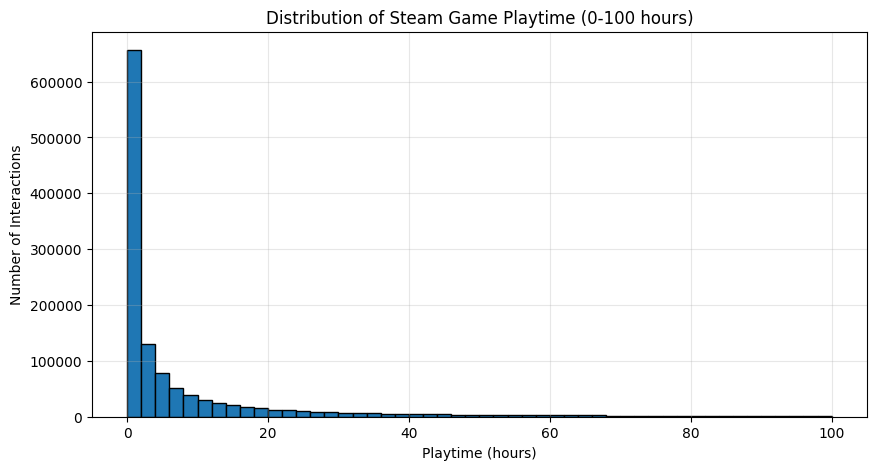


플레이 시간 0분: 311449
플레이 시간 2시간 이상: 637076


In [48]:
# STEP 7-2. 사용자 플레이 시간 분포 분석

import pandas as pd
import matplotlib.pyplot as plt

# 1. 플레이 시간 확인
print("=== 플레이 시간 기본 통계 (분) ===")
display(interactions_final["playtime_forever"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
))

# 2. 플레이 시간 단위를 시간으로 변환
interactions_final["playtime_hours"] = (
    interactions_final["playtime_forever"] / 60
)

print("\n=== 플레이 시간 기본 통계 (시간) ===")
display(interactions_final["playtime_hours"].describe())

# 3. 플레이 시간별 기록 수
thresholds = [0, 1, 2, 5, 10, 20, 50, 100]

print("\n=== 플레이 시간별 기록 수 ===")
for h in thresholds:
    count = (interactions_final["playtime_hours"] >= h).sum()
    print(f"{h}시간 이상: {count:,}건")

# 4. 플레이 시간 분포 시각화
plt.figure(figsize=(10, 5))

# 100시간 이하만 시각화
plot_data = interactions_final.loc[
    interactions_final["playtime_hours"] <= 100,
    "playtime_hours"
]

plt.hist(plot_data, bins=50, edgecolor="black")
plt.xlabel("Playtime (hours)")
plt.ylabel("Number of Interactions")
plt.title("Distribution of Steam Game Playtime (0-100 hours)")
plt.grid(alpha=0.3)
plt.show()

# 5. 플레이 시간이 0인 기록 확인
print("\n플레이 시간 0분:",
      (interactions_final["playtime_forever"] == 0).sum())

print("플레이 시간 2시간 이상:",
      (interactions_final["playtime_hours"] >= 2).sum())

=== STEP 7-3 결과 ===
긍정 상호작용 수: 637076
긍정 사용자 수: 62029
긍정 게임 수: 1895

=== 사용자별 긍정 게임 개수 ===


,app_id
count,62029.000000
mean,10.270615
std,14.286518
min,1.000000
25%,3.000000
50%,7.000000
75%,13.000000
max,668.000000



=== 사용자 수 비교 ===
긍정 게임 2개 이상: 54,785명
긍정 게임 3개 이상: 48,989명
긍정 게임 5개 이상: 39,398명
긍정 게임 10개 이상: 22,901명
긍정 게임 20개 이상: 8,324명


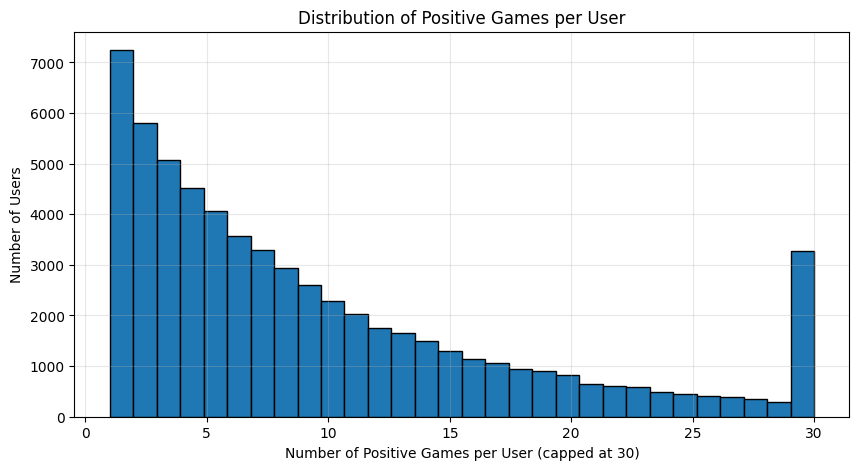

In [49]:
# STEP 7-3. 사용자별 긍정 상호작용 분석

# 1. 2시간 이상 플레이한 기록만 추출
positive_interactions = interactions_final[
    interactions_final["playtime_hours"] >= 2
].copy()

# 2. 사용자별 긍정 게임 개수
user_positive_counts = (
    positive_interactions.groupby("user_id")["app_id"]
    .nunique()
)

# 3. 기본 통계
print("=== STEP 7-3 결과 ===")
print("긍정 상호작용 수:", len(positive_interactions))
print("긍정 사용자 수:", len(user_positive_counts))
print("긍정 게임 수:", positive_interactions["app_id"].nunique())

print("\n=== 사용자별 긍정 게임 개수 ===")
display(user_positive_counts.describe())

# 4. 평가 가능한 사용자 수
print("\n=== 사용자 수 비교 ===")
for n in [2, 3, 5, 10, 20]:
    count = (user_positive_counts >= n).sum()
    print(f"긍정 게임 {n}개 이상: {count:,}명")

# 5. 사용자별 긍정 게임 수 분포
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

user_positive_counts.clip(upper=30).hist(
    bins=30,
    edgecolor="black"
)

plt.xlabel("Number of Positive Games per User (capped at 30)")
plt.ylabel("Number of Users")
plt.title("Distribution of Positive Games per User")
plt.grid(alpha=0.3)
plt.show()


In [50]:

# STEP 7-4. 평가 대상 사용자 선정

# 1. 긍정 게임 5개 이상인 사용자 선택
eligible_users = user_positive_counts[
    user_positive_counts >= 5
].index

# 2. 평가 후보 상호작용 추출
eval_interactions = positive_interactions[
    positive_interactions["user_id"].isin(eligible_users)
].copy()

# 3. 중복 확인
print("=== STEP 7-4 결과 ===")
print("평가 대상 사용자 수:",
      eval_interactions["user_id"].nunique())

print("평가 후보 상호작용 수:",
      len(eval_interactions))

print("평가 대상 게임 수:",
      eval_interactions["app_id"].nunique())

print("\n사용자-게임 중복:",
      eval_interactions.duplicated(
          subset=["user_id", "app_id"]
      ).sum())

# 4. 사용자별 긍정 게임 수 재확인
eval_user_counts = (
    eval_interactions.groupby("user_id")["app_id"]
    .nunique()
)

print("\n=== 사용자별 게임 수 ===")
display(eval_user_counts.describe())

print("\n5개 미만 사용자:",
      (eval_user_counts < 5).sum())

# 5. 상위 데이터 확인
display(eval_interactions.head())


=== STEP 7-4 결과 ===
평가 대상 사용자 수: 39398
평가 후보 상호작용 수: 584952
평가 대상 게임 수: 1892

사용자-게임 중복: 0

=== 사용자별 게임 수 ===


,app_id
count,39398.000000
mean,14.847251
std,16.224058
min,5.000000
25%,7.000000
50%,11.000000
75%,18.000000
max,668.000000



5개 미만 사용자: 0


,item_id,item_name,playtime_forever,playtime_2weeks,user_id,app_id,title,playtime_hours
0,4000,Garry's Mod,642773,7299,wolop,4000,Garry's Mod,10712.883333
1,4000,Garry's Mod,613411,588,76561198039832932,4000,Garry's Mod,10223.516667
2,4000,Garry's Mod,551719,0,jimmynoe,4000,Garry's Mod,9195.316667
3,4000,Garry's Mod,501498,7944,lildoughnut,4000,Garry's Mod,8358.300000
4,4000,Garry's Mod,495058,161,ThisIsWhereIGetOff,4000,Garry's Mod,8250.966667


In [52]:
import os
import subprocess

repo_path = "/content/team_repo"
repo_url = "https://github.com/jinSeong-P/ML-game-recommendation.git"

if not os.path.exists(repo_path):
    subprocess.run(
        ["git", "clone", repo_url, repo_path],
        check=True
    )

print("GitHub 저장소 준비 완료!")

GitHub 저장소 준비 완료!


In [53]:
%cd /content/team_repo

!git fetch origin
!git switch EJ
!git branch --show-current

/content/team_repo
branch 'EJ' set up to track 'origin/EJ'.
Switched to a new branch 'EJ'
EJ
